In [2]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py

/kaggle/working/SpOC2/Morphing Rovers


In [3]:
import numpy as np, time
import matplotlib.pyplot as plt
from morphing_udp import morphing_rover_UDP

udp = morphing_rover_UDP()
lb, ub = map(np.array, udp.get_bounds())
x = np.array(udp.example(), dtype=float)
nota_x = udp.fitness(x)[0]
print("Nota fillestare:", round(nota_x, 3))

Nota fillestare: 7.984


In [4]:
rng = np.random.default_rng(42)

def ndrysho_pak(x, sa_numra=200, sa_shume=1.0):
    y = x.copy()
    n = len(x) - 7
    idx = rng.choice(n, size=sa_numra, replace=False)
    y[idx] += rng.normal(0, sa_shume, sa_numra)
    return np.clip(y, lb, ub)

In [5]:
N = 15
historia = [nota_x]
t = time.time()
for i in range(N):
    y = ndrysho_pak(x)
    nota_y = udp.fitness(y)[0]
    if nota_y < nota_x:
        x, nota_x = y, nota_y
        print(f"Hapi {i+1}: {nota_y:.3f}  U PRANUA, e mira e re: {nota_x:.3f}")
    else:
        print(f"Hapi {i+1}: {nota_y:.3f}  u refuzua")
    historia.append(nota_x)
print("Koha:", round(time.time() - t), "sekonda")

Hapi 1: 9.374  u refuzua
Hapi 2: 10.106  u refuzua
Hapi 3: 5.421  U PRANUA, e mira e re: 5.421
Hapi 4: 5.484  u refuzua
Hapi 5: 6.931  u refuzua
Hapi 6: 5.530  u refuzua
Hapi 7: 6.418  u refuzua
Hapi 8: 6.484  u refuzua
Hapi 9: 9.110  u refuzua
Hapi 10: 6.095  u refuzua
Hapi 11: 7.234  u refuzua
Hapi 12: 6.796  u refuzua
Hapi 13: 5.798  u refuzua
Hapi 14: 9.152  u refuzua
Hapi 15: 7.262  u refuzua
Koha: 385 sekonda


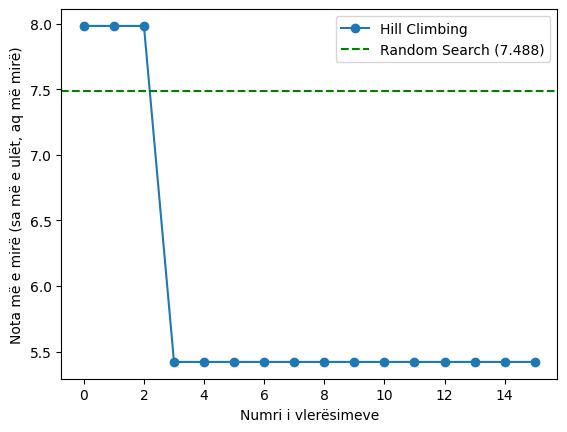

In [6]:
plt.plot(range(N+1), historia, marker="o", label="Hill Climbing")
plt.axhline(7.488, color="green", linestyle="--", label="Random Search (7.488)")
plt.xlabel("Numri i vlerësimeve")
plt.ylabel("Nota më e mirë (sa më e ulët, aq më mirë)")
plt.legend()
plt.savefig("hill_climbing.png", dpi=120, bbox_inches="tight")
plt.show()
np.save("hill_climbing_best.npy", x)